# 1. Dataset Overview

The ResPlan dataset contains 17,000 residential floor plans represented as vector geometries. Each plan contains architectural elements such as walls, bedrooms, bathrooms, kitchens, living areas, doors, windows and other spatial features.

The dataset provides a useful foundation for exploring AI applications in architectural floor-plan analysis, particularly floor-plan similarity search.

# load the dataset and inspect its structure

In [45]:
import pickle

dataset_path = r"D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\01-AI Methods\ResPlan\ResPlan\ResPlan.pkl"

with open(dataset_path, "rb") as f:
    data = pickle.load(f)

print("Dataset loaded successfully!")

Dataset loaded successfully!


# Extract the first plan

In [46]:
plan = data[0]

print("First plan extracted!")
print(type(plan))

First plan extracted!
<class 'dict'>


# Add the utility directory

In [47]:
import sys

utils_path = r"D:\02_LEARNING\02_Masters_IAAC_AI_Architecture\10-Term_01\01-AI Methods\ResPlan"

sys.path.append(utils_path)

print("Utility directory added!")

Utility directory added!


# Import and visualise

<Axes: xlabel='x', ylabel='y'>

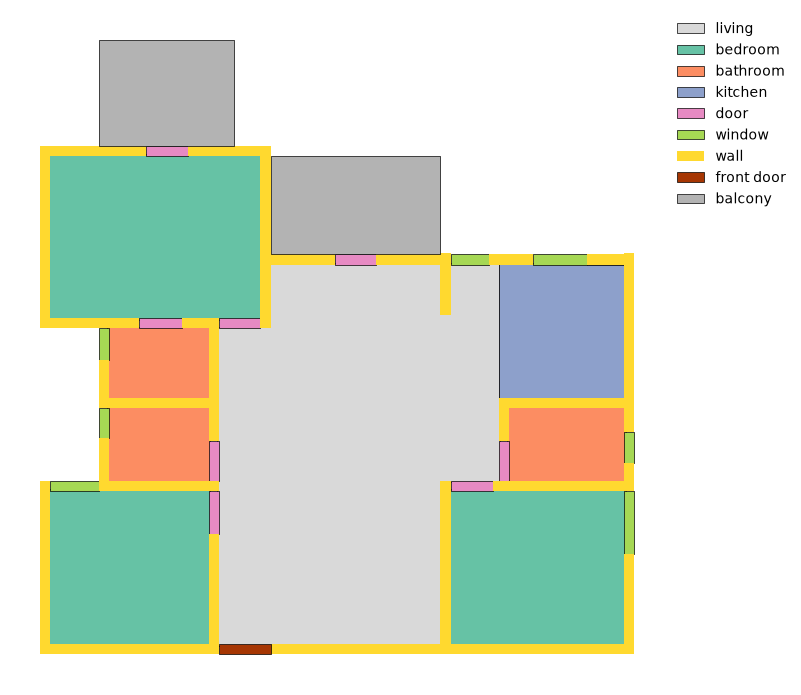

In [48]:
from resplan_utils import plot_plan

plot_plan(plan)

# Inspect the floor plan dimensions

In [49]:
print("Floor Plan ID:", plan["id"])

print("Bounding Box:", plan["wall"].bounds)

print("Width:", plan["wall"].bounds[2] - plan["wall"].bounds[0])

print("Height:", plan["wall"].bounds[3] - plan["wall"].bounds[1])

print("Wall Area:", plan["wall"].area)

Floor Plan ID: 14433
Bounding Box: (-3.8150401989961407, 15.220361568871313, 259.81504019899614, 240.77963843112866)
Width: 263.6300803979923
Height: 225.55927686225735
Wall Area: 5827.997057181324


# Inspect area and wall thickness

In [50]:
print("Net area:", plan["net_area"])
print("Total area:", plan["area"])
print("Wall depth:", plan["wall_depth"])

Net area: 95.65991257881466
Total area: 120.7739
Wall depth: 4.50299826766757


# Calculate the coordinate-to-metre relationship

In [51]:
import math

bbox = plan["wall"].bounds

width = bbox[2] - bbox[0]
height = bbox[3] - bbox[1]

print("Bounding box area:", width * height)
print("Net area:", plan["net_area"])
print("Total area:", plan["area"])
print("Wall depth:", plan["wall_depth"])

print("\nWidth / Height ratio:", width / height)
print("Equivalent width if net area is preserved:",
      math.sqrt(plan["net_area"] * width / height))

Bounding box area: 59464.210293709904
Net area: 95.65991257881466
Total area: 120.7739
Wall depth: 4.50299826766757

Width / Height ratio: 1.1687840290381126
Equivalent width if net area is preserved: 10.57382513763589


# Inspect the overall property geometry

In [52]:
for key in ["land", "inner", "wall"]:
    geom = plan[key]

    print(f"\n{key.upper()}")
    print("Bounds:", geom.bounds)
    print("Area:", geom.area)


LAND
Bounds: (-3.6480198996135584, 15.806570070625856, 260.33575054413006, 290.27004557366854)
Area: 60836.04935571964

INNER
Bounds: (-1.1102230246251565e-16, 19.035401767867448, 255.99999999999994, 236.96459823213254)
Area: 46029.28563780071

WALL
Bounds: (-3.8150401989961407, 15.220361568871313, 259.81504019899614, 240.77963843112866)
Area: 5827.997057181324


In [53]:
bedroom = plan["bedroom"].geoms[0]

print("Bedroom bounds:", bedroom.bounds)
print("Bedroom area:", bedroom.area)

print("\nFirst 5 exterior coordinates:")

for coordinate in list(bedroom.exterior.coords)[:5]:
    print(coordinate)

Bedroom bounds: (177.66374983342956, 19.035401767867448, 255.99999999999994, 88.36565539910274)
Bedroom area: 5431.072092568222

First 5 exterior coordinates:
(255.99999999999994, 88.36565539910274)
(255.99999999999994, 19.035401767867448)
(177.66374983342956, 19.035401767867448)
(177.66374983342956, 88.36565539910274)
(255.99999999999994, 88.36565539910274)


# Visualise all room categories separately

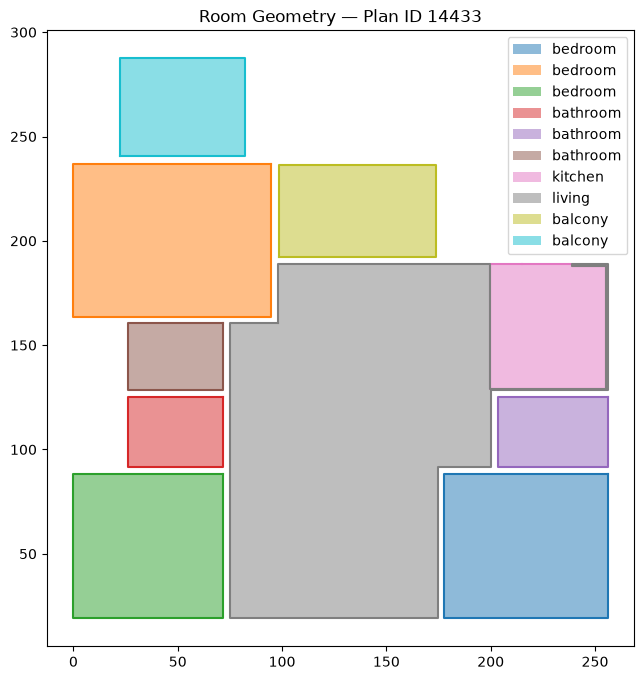

In [54]:
import matplotlib.pyplot as plt

room_types = [
    "bedroom",
    "bathroom",
    "kitchen",
    "living",
    "balcony"
]

fig, ax = plt.subplots(figsize=(10, 8))

for room_type in room_types:
    geom = plan[room_type]

    polygons = (
        list(geom.geoms)
        if geom.geom_type == "MultiPolygon"
        else [geom]
    )

    for polygon in polygons:
        x, y = polygon.exterior.xy
        ax.fill(x, y, alpha=0.5, label=room_type)
        ax.plot(x, y)

ax.set_aspect("equal")
ax.set_title(f"Room Geometry — Plan ID {plan['id']}")
ax.legend()
plt.show()

# understand the dataset size

In [55]:
from collections import Counter

print("Total floor plans:", len(data))

plan_counts = Counter(
    key
    for floor_plan in data
    for key in floor_plan.keys()
)

print("\nGeometry and metadata fields:")
for field, count in plan_counts.items():
    print(f"{field}: {count}")

Total floor plans: 17000

Geometry and metadata fields:
balcony: 13066
bathroom: 17000
bedroom: 16997
door: 17000
garden: 17000
inner: 17000
parking: 17000
pool: 16999
wall: 17000
window: 16950
front_door: 16995
id: 17000
kitchen: 16875
land: 17000
net_area: 17000
area: 17000
neighbor: 17000
living: 17000
wall_depth: 17000
stair: 685
storage: 1781
area_change_sqft: 683


# 2. Geometric and Spatial Structure

The dataset contains both Polygon and MultiPolygon geometries.

MultiPolygon representations are used for several architectural elements, including walls, bedrooms, bathrooms, doors and windows.

Polygon representations are used for elements such as kitchens, living areas and front doors.

Individual architectural elements can contain multiple disconnected geometric regions.

The visualisation experiments confirmed that the plans preserve spatial relationships and can be interpreted as structured vector representations rather than ordinary images.

In [56]:
import pandas as pd

# Total number of floor plans
total_plans = len(data)

# Count how many plans contain each field
field_counts = {}

for floor_plan in data:
    for field in floor_plan.keys():
        field_counts[field] = field_counts.get(field, 0) + 1

# Create statistics table
statistics = []

for field, available in field_counts.items():
    missing = total_plans - available
    availability = (available / total_plans) * 100

    statistics.append({
        "Field": field,
        "Available Plans": available,
        "Missing Plans": missing,
        "Availability (%)": round(availability, 2)
    })

# Convert to DataFrame
stats_df = pd.DataFrame(statistics)

# Sort by availability
stats_df = stats_df.sort_values(
    by="Availability (%)",
    ascending=False
).reset_index(drop=True)

# Display results
print(f"Total Floor Plans: {total_plans:,}")
display(stats_df)

Total Floor Plans: 17,000


,Field,Available Plans,Missing Plans,Availability (%)
0,bathroom,17000,0,100.00
1,door,17000,0,100.00
2,inner,17000,0,100.00
3,garden,17000,0,100.00
4,wall,17000,0,100.00
5,parking,17000,0,100.00
6,wall_depth,17000,0,100.00
7,neighbor,17000,0,100.00
8,land,17000,0,100.00
9,id,17000,0,100.00


Export the statistics

In [57]:
stats_df.to_csv("resplan_dataset_statistics.csv", index=False)

print("Statistics exported successfully!")

Statistics exported successfully!


EDA — Step 1: Identify missing and empty geometries

Missing field: The floor plan doesn't contain the key at all.

None value: The key exists, but its value is None.

Empty geometry: The geometry exists but contains no actual shapes.

Valid geometry: The geometry contains usable spatial information.

In [58]:
import pandas as pd

geometry_fields = [
    "balcony", "bathroom", "bedroom", "door",
    "garden", "parking", "pool", "wall",
    "window", "front_door", "kitchen",
    "land", "living", "stair", "storage"
]

eda_results = []

for field in geometry_fields:

    missing_key = 0
    none_value = 0
    empty_geometry = 0
    valid_geometry = 0

    for plan_data in data:

        if field not in plan_data:
            missing_key += 1

        elif plan_data[field] is None:
            none_value += 1

        elif plan_data[field].is_empty:
            empty_geometry += 1

        else:
            valid_geometry += 1

    eda_results.append({
        "Feature": field,
        "Missing Key": missing_key,
        "None Values": none_value,
        "Empty Geometry": empty_geometry,
        "Valid Geometry": valid_geometry
    })

geometry_eda = pd.DataFrame(eda_results)

display(geometry_eda)

,Feature,Missing Key,None Values,Empty Geometry,Valid Geometry
0,balcony,3934,0,0,13066
1,bathroom,0,0,0,17000
2,bedroom,3,0,0,16997
3,door,0,0,0,17000
4,garden,0,0,16457,543
5,parking,0,0,16663,337
6,pool,1,0,16998,1
7,wall,0,0,0,17000
8,window,50,1,0,16949
9,front_door,5,0,0,16995


Visualise feature availability

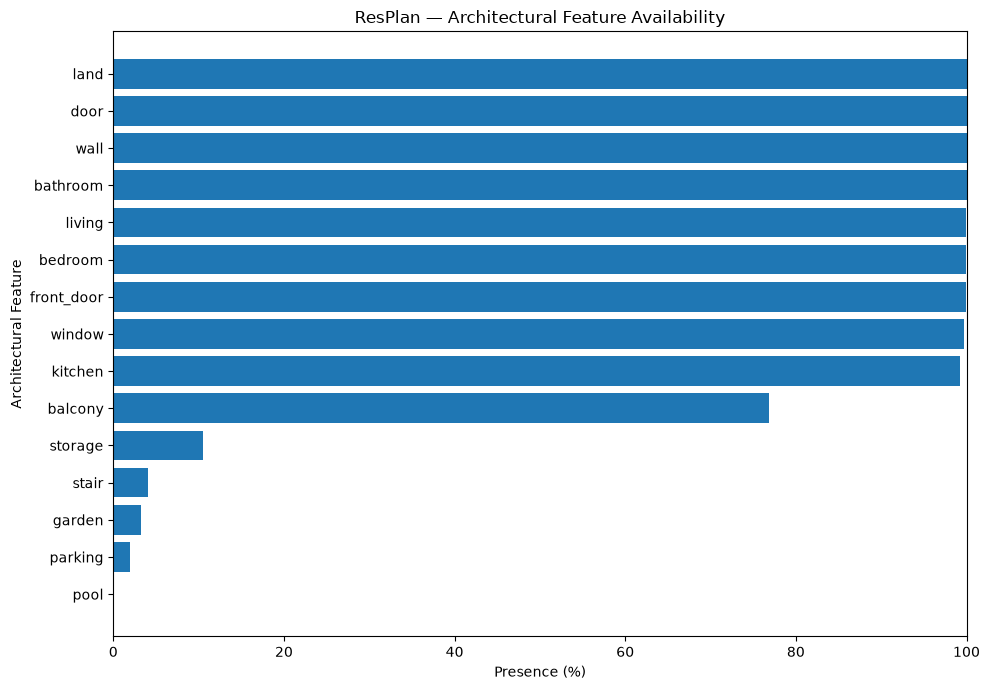

In [59]:
import matplotlib.pyplot as plt

# Calculate feature presence
feature_presence = geometry_eda.copy()

feature_presence["Present (%)"] = (
    feature_presence["Valid Geometry"] / len(data)
) * 100

feature_presence = feature_presence.sort_values(
    "Present (%)",
    ascending=True
)

# Plot
plt.figure(figsize=(10, 7))

plt.barh(
    feature_presence["Feature"],
    feature_presence["Present (%)"]
)

plt.xlabel("Presence (%)")
plt.ylabel("Architectural Feature")
plt.title("ResPlan — Architectural Feature Availability")
plt.xlim(0, 100)

plt.tight_layout()
plt.show()

Analyse relationships between architectural features

Do plans with balconies also tend to have gardens?

Are parking spaces associated with larger properties?

Do plans with stairs tend to have larger floor areas?

How frequently do pools and gardens occur together?

feature co-occurrence matrix.

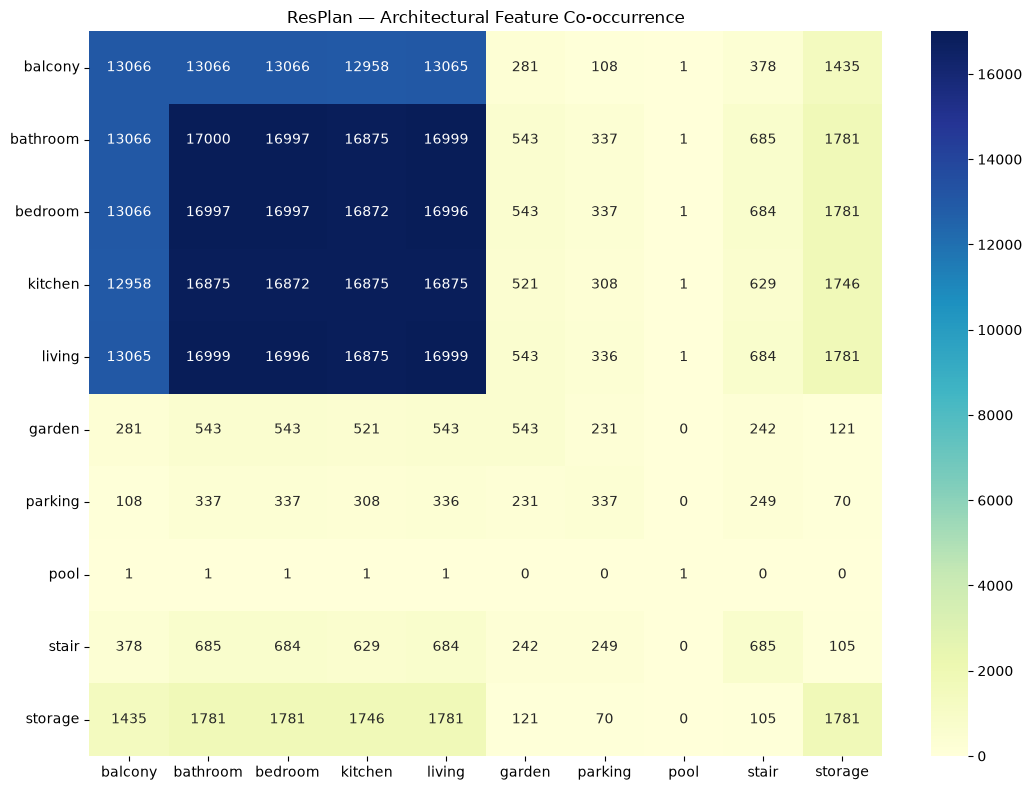

In [60]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

features = [
    "balcony",
    "bathroom",
    "bedroom",
    "kitchen",
    "living",
    "garden",
    "parking",
    "pool",
    "stair",
    "storage"
]

# Create binary presence/absence data
presence_data = []

for floor_plan in data:
    row = {}

    for feature in features:
        if feature in floor_plan:
            geom = floor_plan[feature]
            row[feature] = (
                1 if geom is not None and not geom.is_empty else 0
            )
        else:
            row[feature] = 0

    presence_data.append(row)

presence_df = pd.DataFrame(presence_data)

# Calculate feature co-occurrence
cooccurrence = presence_df.T.dot(presence_df)

# Plot heatmap
plt.figure(figsize=(11, 8))

sns.heatmap(
    cooccurrence,
    annot=True,
    fmt="d",
    cmap="YlGnBu"
)

plt.title("ResPlan — Architectural Feature Co-occurrence")
plt.tight_layout()
plt.show()

A. Core residential spaces

Bedroom, bathroom, kitchen and living spaces have very high co-occurrence.

This tells us that these features form the common spatial composition of the dataset.

B. Balcony

Balconies occur in 13,066 plans.

Of these:

- 12,958 also contain kitchens.
- 13,065 also contain living spaces.
- 281 also contain gardens.

C. Garden and parking

These features occur less frequently.

- 543 plans contain gardens.
- 337 plans contain parking.
- 231 plans contain both.

D. Pool

Only one plan contains a pool.

This is an important finding: pool-related patterns cannot be meaningfully learned from this dataset.

E. Stair and storage

- 685 plans contain stairs.
- 1,781 plans contain storage.

These are relatively uncommon compared with the core residential spaces.

investigate area relationships

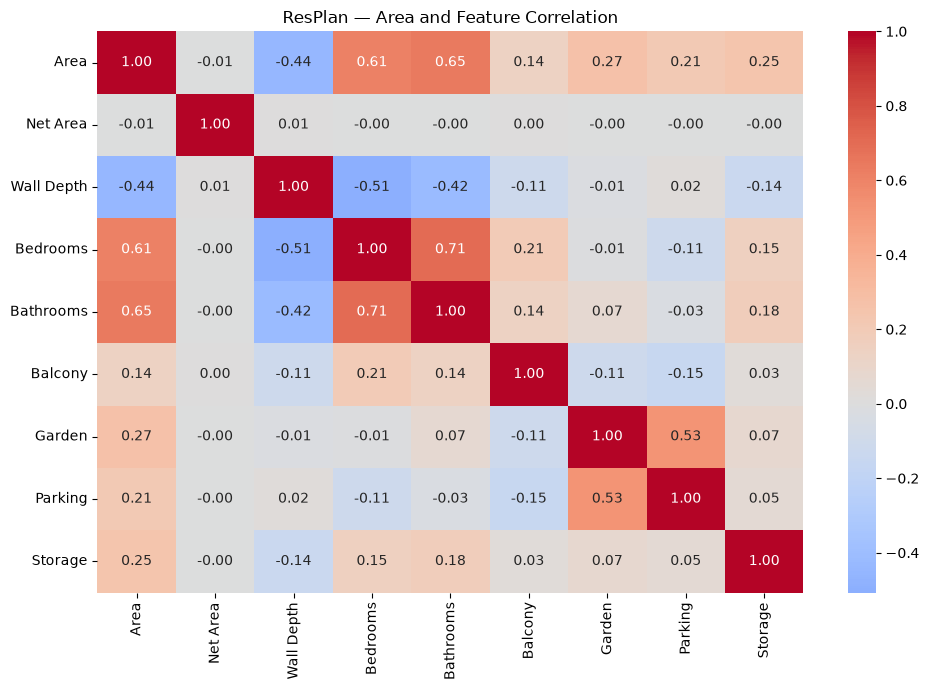

In [61]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def count_polygons(geometry):
    if geometry is None or geometry.is_empty:
        return 0

    if geometry.geom_type == "Polygon":
        return 1

    if geometry.geom_type == "MultiPolygon":
        return len(geometry.geoms)

    return 0


area_data = []

for p in data:

    balcony = p.get("balcony")
    garden = p.get("garden")
    parking = p.get("parking")
    storage = p.get("storage")

    area_data.append({
        "Plan ID": p["id"],
        "Area": p["area"],
        "Net Area": p["net_area"],
        "Wall Depth": p["wall_depth"],

        "Bedrooms": count_polygons(p.get("bedroom")),
        "Bathrooms": count_polygons(p.get("bathroom")),

        "Balcony": int(count_polygons(balcony) > 0),
        "Garden": int(count_polygons(garden) > 0),
        "Parking": int(count_polygons(parking) > 0),
        "Storage": int(count_polygons(storage) > 0)
    })

area_df = pd.DataFrame(area_data)

correlation = area_df.drop(columns="Plan ID").corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("ResPlan — Area and Feature Correlation")
plt.tight_layout()
plt.show()

Key findings

Bedrooms and bathrooms

Larger values of Area tend to be associated with more bedroom and bathroom polygons.

Garden and parking

Garden and parking have a positive correlation of 0.53. Plans containing one tend to contain the other more often.

Wall depth

Wall depth has a negative correlation with area (-0.44). This is an interesting relationship worth investigating.

Net area

The correlation between Area and Net Area is almost zero (-0.01). This is unexpected and deserves further investigation.

investigate area distributions

,Area,Net Area,Wall Depth,Bedrooms,Bathrooms
count,17000.00,1.700000e+04,17000.00,17000.0,17000.00
mean,120.69,4.707662e+06,4.19,2.4,2.38
std,55.24,6.070016e+08,0.67,0.8,0.70
min,0.09,0.000000e+00,2.22,0.0,1.00
25%,87.14,0.000000e+00,3.69,2.0,2.00
50%,109.63,6.795000e+01,4.14,2.0,2.00
75%,140.77,1.048100e+02,4.64,3.0,3.00
max,712.94,7.914086e+10,7.18,7.0,7.00


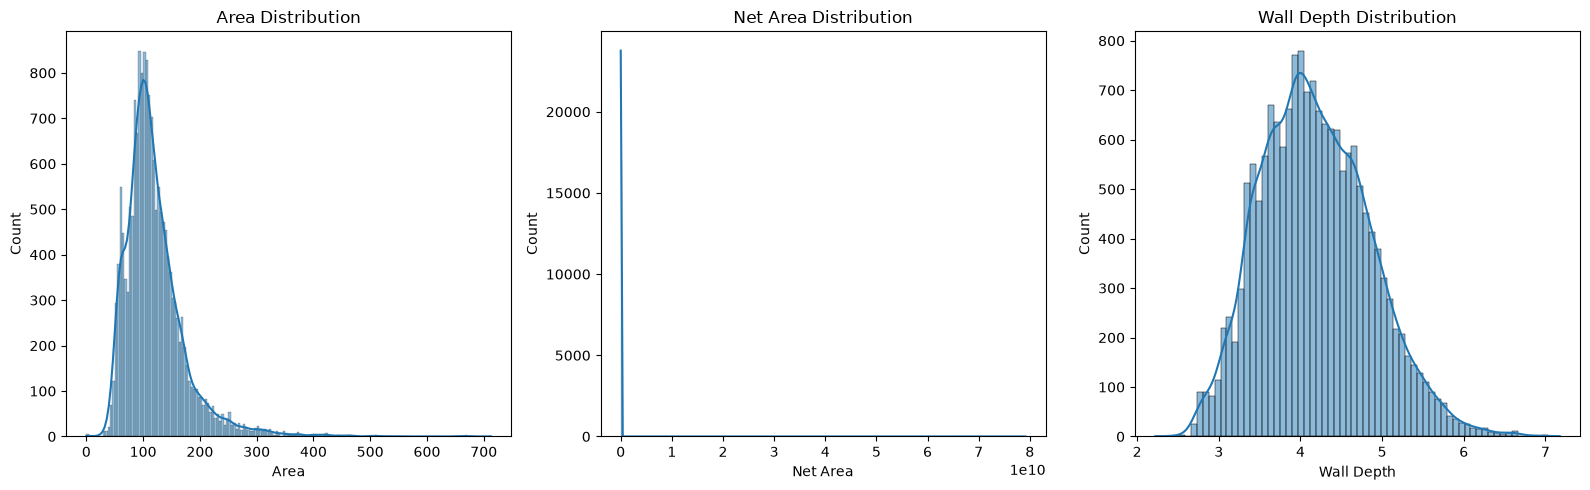

In [62]:
# Statistical summary
display(
    area_df[["Area", "Net Area", "Wall Depth",
             "Bedrooms", "Bathrooms"]].describe().round(2)
)

# Distribution plots
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.histplot(area_df["Area"], kde=True, ax=axes[0])
axes[0].set_title("Area Distribution")

sns.histplot(area_df["Net Area"], kde=True, ax=axes[1])
axes[1].set_title("Net Area Distribution")

sns.histplot(area_df["Wall Depth"], kde=True, ax=axes[2])
axes[2].set_title("Wall Depth Distribution")

plt.tight_layout()
plt.show()

Feature	What we discovered	Our conclusion

Area -	Most values are concentrated around 100–140

Net Area -	Extremely large maximum values

Wall Depth	- Values concentrated around 4

Investigate unusual Net Area values

In [63]:
# Find the 20 floor plans with the largest Net Area

net_area_outliers = area_df.sort_values(
    by="Net Area",
    ascending=False
)

display(
    net_area_outliers[
        ["Plan ID", "Net Area", "Area", "Wall Depth"]
    ].head(20)
)

,Plan ID,Net Area,Area,Wall Depth
3544,2525,7.914086e+10,81.383028,4.695959
16975,10779,6.200957e+08,95.597187,5.021922
11532,14838,1.098105e+08,130.528715,3.918367
11107,1501,2.555231e+07,109.439734,4.439142
16931,6381,2.510554e+07,114.177787,4.668693
2498,7596,1.320714e+07,125.419050,4.187773
4338,9132,9.614436e+06,141.212560,3.741778
11694,340,6.823924e+06,106.838450,5.052632
810,11042,6.784979e+06,101.171367,4.992416
12143,9461,4.788231e+06,113.155854,4.663060


# Outliers

In [22]:
# Calculate 99th percentile thresholds

area_threshold = area_df["Area"].quantile(0.99)
net_area_threshold = area_df["Net Area"].quantile(0.99)

print("99th percentile thresholds")
print("--------------------------------")
print(f"Area threshold: {area_threshold:.2f}")
print(f"Net Area threshold: {net_area_threshold:.2f}")

# Count extreme values
area_outliers = area_df[area_df["Area"] > area_threshold]
net_area_outliers = area_df[area_df["Net Area"] > net_area_threshold]

print("\nPotential extreme values")
print("--------------------------------")
print(f"Area outliers: {len(area_outliers)}")
print(f"Net Area outliers: {len(net_area_outliers)}")

99th percentile thresholds
--------------------------------
Area threshold: 323.87
Net Area threshold: 18115.96

Potential extreme values
--------------------------------
Area outliers: 170
Net Area outliers: 170


In [24]:
# Extract IDs of outliers from each column

area_outlier_ids = set(
    area_outliers["Plan ID"]
)

net_area_outlier_ids = set(
    net_area_outliers["Plan ID"]
)

# Compare

common_outliers = area_outlier_ids & net_area_outlier_ids

only_area = area_outlier_ids - net_area_outlier_ids
only_net_area = net_area_outlier_ids - area_outlier_ids

print("OUTLIER COMPARISON")
print("----------------------------")
print("Area outliers:", len(area_outlier_ids))
print("Net Area outliers:", len(net_area_outlier_ids))
print("Common outliers:", len(common_outliers))
print("Only Area:", len(only_area))
print("Only Net Area:", len(only_net_area))

OUTLIER COMPARISON
----------------------------
Area outliers: 170
Net Area outliers: 170
Common outliers: 0
Only Area: 170
Only Net Area: 170


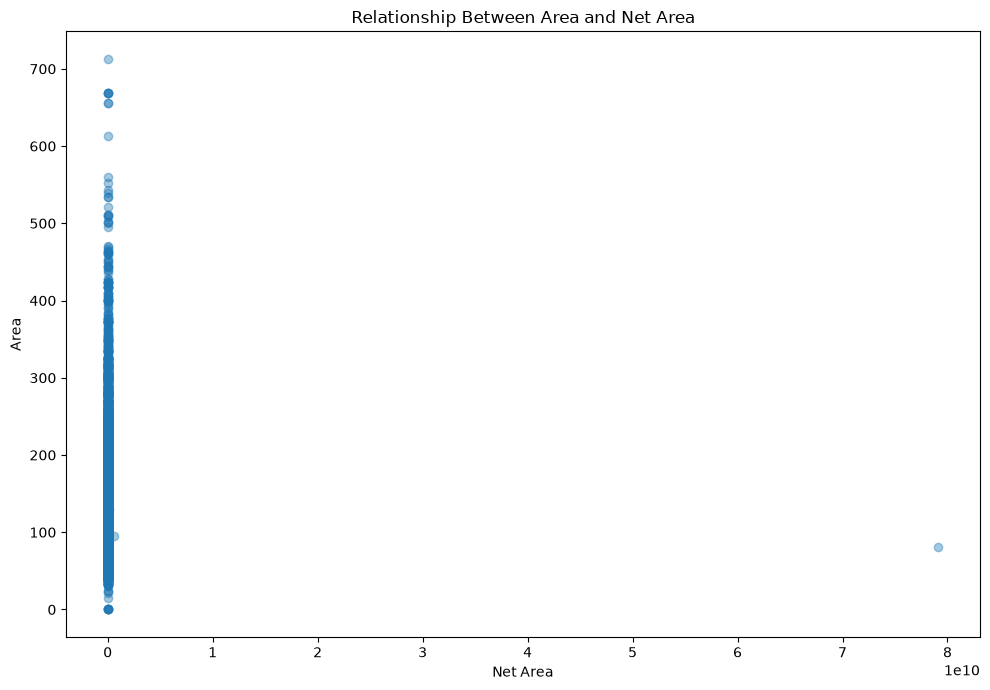

In [25]:
plt.figure(figsize=(10, 7))

plt.scatter(
    area_df["Net Area"],
    area_df["Area"],
    alpha=0.4
)

plt.xlabel("Net Area")
plt.ylabel("Area")
plt.title("Relationship Between Area and Net Area")

plt.tight_layout()
plt.show()

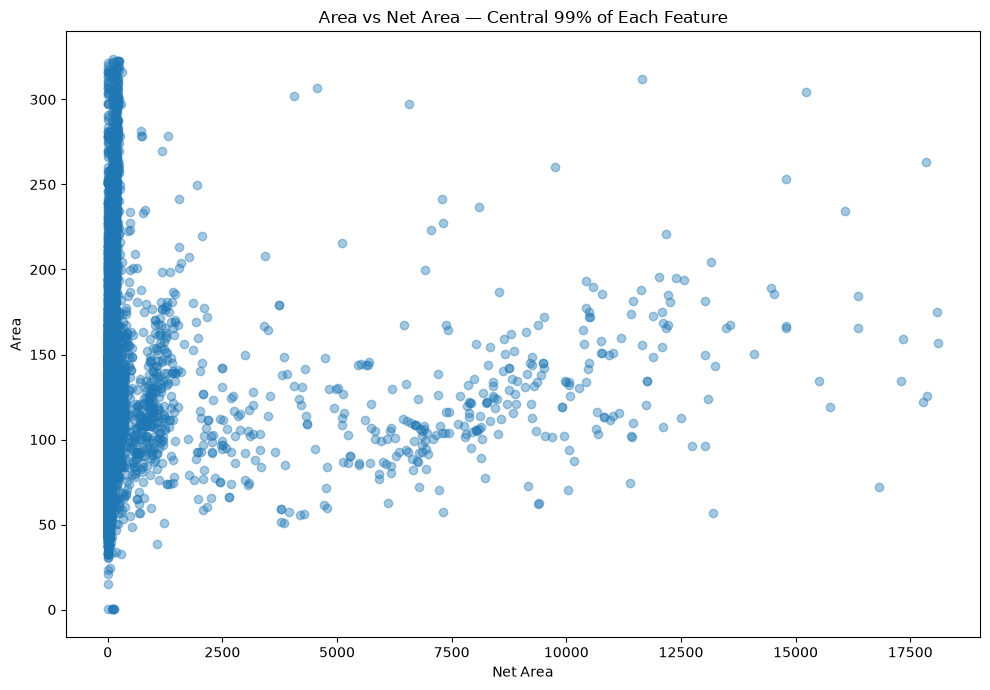

Original records: 17000
Records displayed: 16660


In [26]:
# Calculate 99th percentile thresholds
area_limit = area_df["Area"].quantile(0.99)
net_area_limit = area_df["Net Area"].quantile(0.99)

# Keep observations below both thresholds
normal_data = area_df[
    (area_df["Area"] <= area_limit) &
    (area_df["Net Area"] <= net_area_limit)
]

# Plot
plt.figure(figsize=(10, 7))

plt.scatter(
    normal_data["Net Area"],
    normal_data["Area"],
    alpha=0.4
)

plt.xlabel("Net Area")
plt.ylabel("Area")
plt.title("Area vs Net Area — Central 99% of Each Feature")

plt.tight_layout()
plt.show()

print("Original records:", len(area_df))
print("Records displayed:", len(normal_data))

In [27]:
print("Original correlation:")
print(area_df["Area"].corr(area_df["Net Area"]))

print("\nCorrelation after filtering:")
print(normal_data["Area"].corr(normal_data["Net Area"]))

Original correlation:
-0.005481963808706406

Correlation after filtering:
0.0758661468492744


In [28]:
# Inspect data types
print("DATA TYPES")
print(area_df[["Area", "Net Area"]].dtypes)

# Inspect unique values
print("\nUNIQUE VALUES")
print("Area:", area_df["Area"].nunique())
print("Net Area:", area_df["Net Area"].nunique())

# Inspect zero and negative values
print("\nINVALID OR ZERO VALUES")
print("Area <= 0:", (area_df["Area"] <= 0).sum())
print("Net Area <= 0:", (area_df["Net Area"] <= 0).sum())

# Show examples
display(area_df[["Plan ID", "Area", "Net Area"]].sample(10, random_state=42))

DATA TYPES
Area        float64
Net Area    float64
dtype: object

UNIQUE VALUES
Area: 2467
Net Area: 11078

INVALID OR ZERO VALUES
Area <= 0: 0
Net Area <= 0: 5458


,Plan ID,Area,Net Area
10941,5278,56.206315,15.341511
5250,12057,61.780495,44.705605
10292,15407,94.761060,0.494136
2266,6446,269.418700,73.195792
6398,15448,117.986810,94.627021
4064,10542,102.193300,86.494613
8018,15237,105.259099,57.477851
3934,15332,129.135170,94.637007
16287,11089,111.483600,81.748333
8875,8083,99.870725,0.000000


In [29]:
# Categorise Net Area values

net_area_categories = {
    "Zero": (area_df["Net Area"] == 0).sum(),

    "Very Small (0–10)": (
        (area_df["Net Area"] > 0) &
        (area_df["Net Area"] <= 10)
    ).sum(),

    "Small (10–30)": (
        (area_df["Net Area"] > 10) &
        (area_df["Net Area"] <= 30)
    ).sum(),

    "Normal (30–200)": (
        (area_df["Net Area"] > 30) &
        (area_df["Net Area"] <= 200)
    ).sum(),

    "Large (>200)": (
        area_df["Net Area"] > 200
    ).sum()
}

net_area_distribution = pd.DataFrame(
    list(net_area_categories.items()),
    columns=["Category", "Number of Plans"]
)

net_area_distribution["Percentage"] = (
    net_area_distribution["Number of Plans"] / len(data) * 100
).round(2)

display(net_area_distribution)

,Category,Number of Plans,Percentage
0,Zero,5458,32.11
1,Very Small (0–10),667,3.92
2,Small (10–30),502,2.95
3,Normal (30–200),9021,53.06
4,Large (>200),1352,7.95


In [30]:
# Select plans with zero Net Area
zero_net_area_plans = [
    p for p in data
    if p["net_area"] == 0
]

# Compare with plans having normal Net Area
normal_net_area_plans = [
    p for p in data
    if 30 < p["net_area"] <= 200
]

# Calculate average Area
zero_mean_area = sum(
    p["area"] for p in zero_net_area_plans
) / len(zero_net_area_plans)

normal_mean_area = sum(
    p["area"] for p in normal_net_area_plans
) / len(normal_net_area_plans)

print("ZERO NET AREA PLANS")
print("----------------------------")
print("Number of plans:", len(zero_net_area_plans))
print("Average Area:", round(zero_mean_area, 2))

print("\nNORMAL NET AREA PLANS")
print("----------------------------")
print("Number of plans:", len(normal_net_area_plans))
print("Average Area:", round(normal_mean_area, 2))

ZERO NET AREA PLANS
----------------------------
Number of plans: 5458
Average Area: 95.54

NORMAL NET AREA PLANS
----------------------------
Number of plans: 9021
Average Area: 133.33


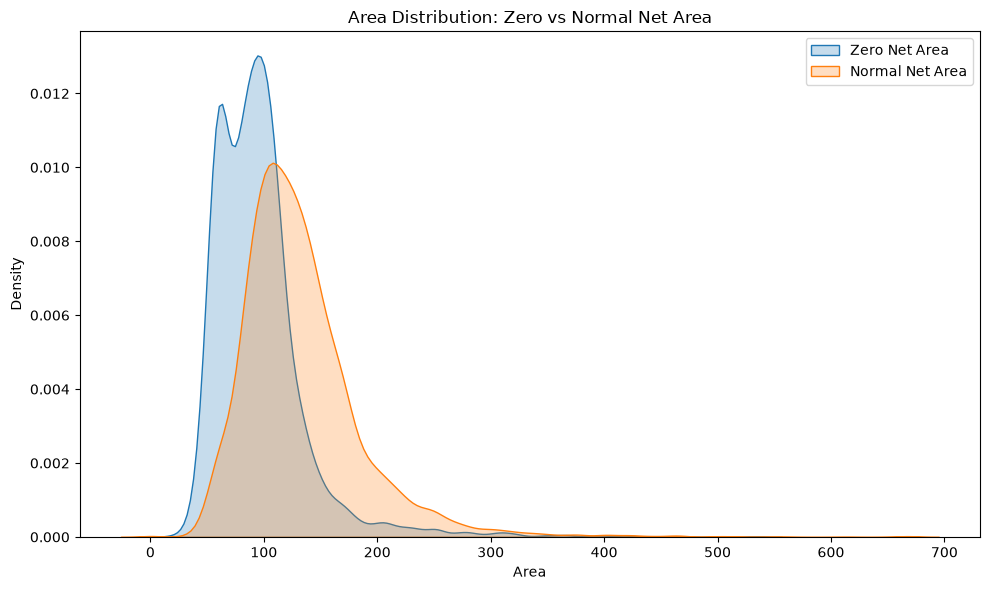

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

zero_group = area_df[area_df["Net Area"] == 0]

normal_group = area_df[
    (area_df["Net Area"] > 30) &
    (area_df["Net Area"] <= 200)
]

plt.figure(figsize=(10, 6))

sns.kdeplot(
    zero_group["Area"],
    label="Zero Net Area",
    fill=True
)

sns.kdeplot(
    normal_group["Area"],
    label="Normal Net Area",
    fill=True
)

plt.xlabel("Area")
plt.ylabel("Density")
plt.title("Area Distribution: Zero vs Normal Net Area")
plt.legend()
plt.tight_layout()
plt.show()

# Do zero Net Area plans contain actual rooms?

In [33]:
# Identify the two groups
zero_mask = area_df["Net Area"] == 0

normal_mask = (
    (area_df["Net Area"] > 30) &
    (area_df["Net Area"] <= 200)
)

# Core architectural features available in presence_df
core_features = [
    "bedroom",
    "bathroom",
    "kitchen",
    "living"
]

# Compare feature availability
comparison = pd.DataFrame({
    "Zero Net Area (%)": (
        presence_df.loc[zero_mask, core_features].mean() * 100
    ).round(2),

    "Normal Net Area (%)": (
        presence_df.loc[normal_mask, core_features].mean() * 100
    ).round(2)
})

display(comparison)

,Zero Net Area (%),Normal Net Area (%)
bedroom,99.96,99.99
bathroom,100.00,100.00
kitchen,99.38,99.17
living,99.98,100.00


Zero Net Area does not indicate that the floor plan is missing its main architectural spaces.

It is more likely an issue with the area attribute itself, although we haven't established the exact cause.

# Investigate geometry quality

In [34]:
from collections import defaultdict

geometry_fields = [
    "wall",
    "bedroom",
    "bathroom",
    "kitchen",
    "living",
    "door",
    "window"
]

geometry_quality = defaultdict(
    lambda: {"valid": 0, "invalid": 0, "empty": 0, "missing": 0}
)

for p in data:

    for field in geometry_fields:

        geom = p.get(field)

        if geom is None:
            geometry_quality[field]["missing"] += 1

        elif geom.is_empty:
            geometry_quality[field]["empty"] += 1

        elif geom.is_valid:
            geometry_quality[field]["valid"] += 1

        else:
            geometry_quality[field]["invalid"] += 1

geometry_quality_df = pd.DataFrame.from_dict(
    geometry_quality,
    orient="index"
)

display(geometry_quality_df)

,valid,invalid,empty,missing
wall,17000,0,0,0
bedroom,16990,7,0,3
bathroom,16995,5,0,0
kitchen,16875,0,0,125
living,16999,0,0,1
door,16636,364,0,0
window,16550,399,0,51


WHY doors and windows are invalid

In [35]:
from shapely.validation import explain_validity
from collections import Counter

invalid_reasons = {
    "door": Counter(),
    "window": Counter()
}

invalid_examples = {
    "door": [],
    "window": []
}

for p in data:

    for feature in ["door", "window"]:

        geom = p.get(feature)

        if geom is not None and not geom.is_empty and not geom.is_valid:

            reason = explain_validity(geom)

            invalid_reasons[feature][reason] += 1

            if len(invalid_examples[feature]) < 5:
                invalid_examples[feature].append({
                    "Plan ID": p["id"],
                    "Reason": reason
                })

for feature in ["door", "window"]:

    print(f"\n{feature.upper()} — INVALID GEOMETRY REASONS")
    print("-----------------------------------")

    for reason, count in invalid_reasons[feature].most_common():
        print(f"{reason}: {count}")

    print("\nExample records:")
    display(pd.DataFrame(invalid_examples[feature]))


DOOR — INVALID GEOMETRY REASONS
-----------------------------------
Self-intersection[108.846015578191 149.569802276812]: 3
Self-intersection[189.200926164137 63.1273475688192]: 2
Self-intersection[100.610346282164 136.865494497066]: 2
Self-intersection[79.5860122314568 110.802195389682]: 2
Self-intersection[91.2130312263377 134.95410255569]: 1
Self-intersection[52.7340823970037 69.9925093632959]: 1
Self-intersection[44.5653997024212 205.842283240904]: 1
Self-intersection[71.1629871376464 158.691495488577]: 1
Self-intersection[50.7868453105968 42.9330085261876]: 1
Self-intersection[183.59429436198 104.557169076215]: 1
Self-intersection[111.028894810911 131.863341018654]: 1
Self-intersection[190.075506689628 127.084382037356]: 1
Self-intersection[134.928117535716 172.23380954527]: 1
Self-intersection[120.886515353805 194.712950600801]: 1
Self-intersection[208.413476391266 129.731390640003]: 1
Self-intersection[165.556886227545 216.451732049919]: 1
Self-intersection[117.098329143871 203

,Plan ID,Reason
0,7067,Self-intersection[91.2130312263377 134.9541025...
1,8129,Self-intersection[52.7340823970037 69.99250936...
2,8271,Self-intersection[44.5653997024212 205.8422832...
3,15468,Self-intersection[71.1629871376464 158.6914954...
4,8820,Self-intersection[50.7868453105968 42.93300852...



WINDOW — INVALID GEOMETRY REASONS
-----------------------------------
Self-intersection[222.218669711676 135.563802455039]: 3
Self-intersection[189.901298701299 230.857142857143]: 2
Self-intersection[75.6009029345373 77.5512415349887]: 2
Self-intersection[14.0293463761672 156.940862605602]: 2
Self-intersection[11.8253475617533 83.7243314484928]: 2
Self-intersection[71.5411457027192 82.106545337298]: 1
Self-intersection[258.908204381539 164.822808383842]: 1
Self-intersection[259.450577663671 65.7800599058622]: 1
Self-intersection[188.50889870752 232.653755626213]: 1
Self-intersection[194.365382086019 107.544916480337]: 1
Self-intersection[12.9888524590164 79.8426229508197]: 1
Self-intersection[91.1656234139739 139.693452884453]: 1
Self-intersection[58.8440748440748 194.012474012474]: 1
Self-intersection[145.489130131443 63.1873412775933]: 1
Self-intersection[235.227428571429 114.102857142857]: 1
Self-intersection[175.299474605954 39.0052539404553]: 1
Self-intersection[155.380418636057 

,Plan ID,Reason
0,13553,Self-intersection[71.5411457027192 82.10654533...
1,5268,Self-intersection[258.908204381539 164.8228083...
2,14171,Self-intersection[259.450577663671 65.78005990...
3,12165,Self-intersection[188.50889870752 232.65375562...
4,12868,Self-intersection[194.365382086019 107.5449164...


invalid polygons are due to self intersection

# visualise an invalid door

Plan ID: 7067
Validity issue: Self-intersection[91.2130312263377 134.95410255569]


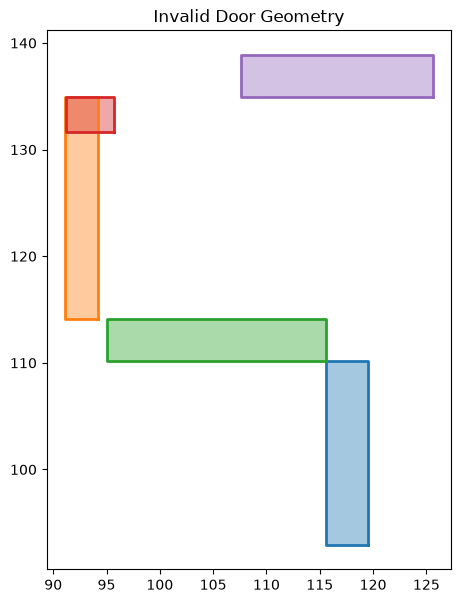

In [36]:
import matplotlib.pyplot as plt

# Find the first plan containing invalid door geometry
invalid_door_plan = next(
    p for p in data
    if p.get("door") is not None
    and not p["door"].is_empty
    and not p["door"].is_valid
)

print("Plan ID:", invalid_door_plan["id"])
print("Validity issue:", explain_validity(invalid_door_plan["door"]))

# Plot the door geometry
fig, ax = plt.subplots(figsize=(7, 7))

door = invalid_door_plan["door"]

polygons = (
    list(door.geoms)
    if door.geom_type == "MultiPolygon"
    else [door]
)

for polygon in polygons:
    x, y = polygon.exterior.xy
    ax.plot(x, y, linewidth=2)
    ax.fill(x, y, alpha=0.4)

ax.set_aspect("equal")
ax.set_title("Invalid Door Geometry")
plt.show()

In [37]:
door = invalid_door_plan["door"]
polygons = list(door.geoms)

for i in range(len(polygons)):
    for j in range(i + 1, len(polygons)):
        intersection = polygons[i].intersection(polygons[j])

        if not intersection.is_empty:
            print(
                f"Polygon {i+1} and Polygon {j+1}: "
                f"Intersection area = {intersection.area:.4f}"
            )

Polygon 1 and Polygon 3: Intersection area = 0.0000
Polygon 2 and Polygon 4: Intersection area = 9.8455


The invalid door geometry is caused by overlapping polygon regions. The intersection area of 9.8455 confirms a genuine overlap.

In [38]:
overlapping_doors = 0
total_invalid_doors = 0

for p in data:
    door = p.get("door")

    if door is None or door.is_empty or door.is_valid:
        continue

    total_invalid_doors += 1
    polygons = list(door.geoms)

    has_overlap = False

    for i in range(len(polygons)):
        for j in range(i + 1, len(polygons)):
            if polygons[i].intersection(polygons[j]).area > 1e-6:
                has_overlap = True
                break
        if has_overlap:
            break

    if has_overlap:
        overlapping_doors += 1

print("Total invalid door geometries:", total_invalid_doors)
print("Invalid doors with polygon overlap:", overlapping_doors)
print(
    "Percentage:",
    round(overlapping_doors / total_invalid_doors * 100, 2),
    "%"
)

Total invalid door geometries: 364
Invalid doors with polygon overlap: 151
Percentage: 41.48 %


364 door geometries (2.14% of all 17,000 plans) were invalid. Of these, 151 (41.48%) contained overlapping polygon regions. The remaining invalid geometries require further investigation.

# investigate the invalid window geometries

In [39]:
invalid_windows = [
    p for p in data
    if p.get("window") is not None
    and not p["window"].is_empty
    and not p["window"].is_valid
]

print("Invalid window geometries:", len(invalid_windows))

window = invalid_windows[0]["window"]

print("Plan ID:", invalid_windows[0]["id"])
print("Validity issue:", explain_validity(window))

Invalid window geometries: 399
Plan ID: 13553
Validity issue: Self-intersection[71.5411457027192 82.106545337298]


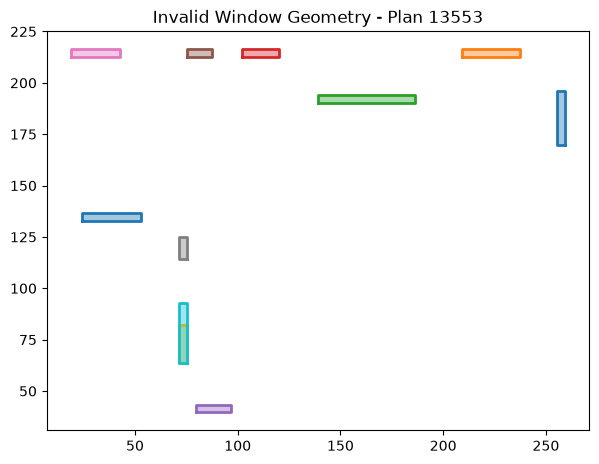

In [40]:
import matplotlib.pyplot as plt

window = invalid_windows[0]["window"]

fig, ax = plt.subplots(figsize=(7, 7))

polygons = list(window.geoms) if window.geom_type == "MultiPolygon" else [window]

for polygon in polygons:
    x, y = polygon.exterior.xy
    ax.plot(x, y, linewidth=2)
    ax.fill(x, y, alpha=0.4)

ax.set_aspect("equal")
ax.set_title("Invalid Window Geometry - Plan 13553")
plt.show()

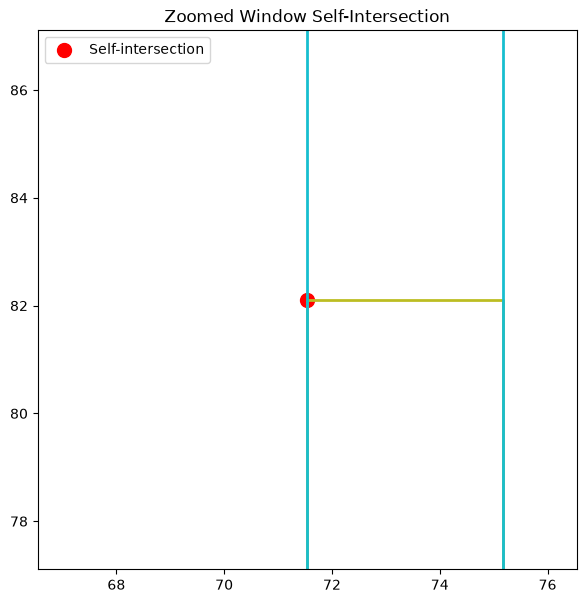

In [41]:
import matplotlib.pyplot as plt

window = invalid_windows[0]["window"]

fig, ax = plt.subplots(figsize=(7, 7))

polygons = list(window.geoms) if window.geom_type == "MultiPolygon" else [window]

for polygon in polygons:
    x, y = polygon.exterior.xy
    ax.plot(x, y, linewidth=2)

# Mark the reported self-intersection
x_issue = 71.5411457027192
y_issue = 82.106545337298

ax.scatter(x_issue, y_issue, color="red", s=100, label="Self-intersection")

ax.set_xlim(x_issue - 5, x_issue + 5)
ax.set_ylim(y_issue - 5, y_issue + 5)
ax.set_aspect("equal")
ax.legend()
ax.set_title("Zoomed Window Self-Intersection")

plt.show()

In [42]:
from shapely.validation import explain_validity

window = invalid_windows[0]["window"]
polygons = list(window.geoms)

for i, polygon in enumerate(polygons):
    if not polygon.is_valid:
        print("Invalid polygon number:", i + 1)
        print("Validity issue:", explain_validity(polygon))

        coords = list(polygon.exterior.coords)

        for j, (x, y) in enumerate(coords):
            if abs(x - 71.5411) < 2 and abs(y - 82.1065) < 2:
                print("\nNearby boundary coordinates:")
                for k in range(max(0, j - 2), min(len(coords), j + 3)):
                    print(coords[k])

In [43]:
overlapping_windows = 0
total_invalid_windows = 0

for p in data:
    window = p.get("window")

    if window is None or window.is_empty or window.is_valid:
        continue

    total_invalid_windows += 1
    polygons = list(window.geoms)

    has_overlap = False

    for i in range(len(polygons)):
        for j in range(i + 1, len(polygons)):
            if polygons[i].intersection(polygons[j]).area > 1e-6:
                has_overlap = True
                break
        if has_overlap:
            break

    if has_overlap:
        overlapping_windows += 1

print("Total invalid windows:", total_invalid_windows)
print("Invalid windows with polygon overlap:", overlapping_windows)
print(
    "Percentage:",
    round(overlapping_windows / total_invalid_windows * 100, 2),
    "%"
)

Total invalid windows: 399
Invalid windows with polygon overlap: 47
Percentage: 11.78 %


In [44]:
geometry_quality_df["invalid_percentage"] = (
    geometry_quality_df["invalid"] /
    (17000) * 100
)

geometry_quality_df["valid_percentage"] = (
    geometry_quality_df["valid"] /
    17000 * 100
)

display(
    geometry_quality_df.round(2)
)

,valid,invalid,empty,missing,invalid_percentage,valid_percentage
wall,17000,0,0,0,0.00,100.00
bedroom,16990,7,0,3,0.04,99.94
bathroom,16995,5,0,0,0.03,99.97
kitchen,16875,0,0,125,0.00,99.26
living,16999,0,0,1,0.00,99.99
door,16636,364,0,0,2.14,97.86
window,16550,399,0,51,2.35,97.35


# 3. Feature Distribution and Statistical Analysis

The exploratory analysis identified variations in room availability, plan area and architectural features.

Key observations:

Bedrooms and bathrooms are present in almost all plans.

Balcony geometry is available in approximately 13,066 plans.

Kitchen geometry is missing in 125 plans.

Net Area contains 5,458 zero values (32.11% of the dataset).

Area and Net Area show almost no linear correlation in the original dataset (Pearson correlation approximately -0.0055).

The Area and Net Area fields also contain extreme values. Their definitions and units should be verified before using them as model features.

## 4. Geometry Quality Assessment

The geometry validity assessment covered seven important architectural elements.

| Geometry | Valid | Invalid | Missing |
|---|---:|---:|---:|
| Wall | 17,000 | 0 | 0 |
| Bedroom | 16,990 | 7 | 3 |
| Bathroom | 16,995 | 5 | 0 |
| Kitchen | 16,875 | 0 | 125 |
| Living | 16,999 | 0 | 1 |
| Door | 16,636 | 364 | 0 |
| Window | 16,550 | 399 | 51 |

The results indicate that the core architectural geometries are generally reliable.

However, doors and windows contain more invalid geometries:

- Door: 364 invalid geometries (2.14%).
- Window: 399 invalid geometries (2.35%).

Further investigation identified overlapping polygon regions in 151 invalid door geometries (41.48% of invalid doors) and 47 invalid window geometries (11.78% of invalid windows).

Other invalid geometries may result from self-intersections or different topological issues.



## 5. Implications for Autoencoder Development

The dataset is a promising candidate for an autoencoder-based floor-plan representation.

However, several preprocessing decisions are required before training:

1. Use the official training, validation and test splits to prevent data leakage.
2. Investigate the treatment of augmented plans.
3. Convert vector geometries into a consistent model input representation.
4. Handle missing and invalid geometries appropriately.
5. Apply consistent scaling and normalisation.
6. Preserve the spatial arrangement of architectural elements during preprocessing.

For the proposed floor-plan similarity search application, the encoder's latent representation will be particularly important. Similarity retrieval can subsequently compare these latent vectors to identify architecturally similar plans.

## 6. Overall Conclusion

The ResPlan dataset provides a substantial collection of structured residential floor plans with generally reliable core architectural geometries.

The exploratory analysis identified potential data-quality concerns involving missing geometries, extreme attribute values and invalid door and window polygons. These issues should be considered during preprocessing rather than automatically removing affected plans.

The dataset is suitable for proceeding to the next stage of the project: preparing consistent model inputs and developing an autoencoder for floor-plan representation learning.